## **ЛАБОРАТОРНАЯ РАБОТА 1**

## **1. Установка библиотеки vk**

In [ ]:
!pip install vk

In [2]:
import time
import pandas as pd
import seaborn as sns
import numpy as np
import math
from matplotlib import pyplot as plt
%matplotlib inline

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

## **2. Подключение по токену**

### **2.1. Создание приложения в разделе "Разработчикам" на сайте vk.com и получение ID приложения**

### **2.4. Запуск сессии**

In [4]:
import vk

# session = vk.Session(access_token='vk1.a.2BbgBoLK1SDU23UpghEmJvpY5VybBW4_qpzoFwn4eHZrD2CPFOC1DnBvvmof4DeUpzIWWpzcBxwXJsDmBe6bQJ1TrRdE85Bzi76QKPKarVgDzihR1juJAG6J08Mp00_rb67yQrNFX2yLUE_BVVhU9-u5yvS0aojlqXOf1X7zGR7ZEyEVdijElyJ10WIz7FcL.......')
# api = vk.API(session)

api = vk.API(access_token='vk1.a.4Sapw03Alo9rv_YCR2U230RZ_DXeTouh1ZNZc3bWIoEtXAH3PJGpSMCVY2R9yZMAK-KOlZ5iZbJVHYmn2kbS5yWeZlao9yqKbzDjj8EuWvWaMkovcYOcq3JVi34xzuCWZSWdQ-aO6fEAeUejjFQJg3OSNMOw-JrNohMlfnfaBvTWu1TcqNEOkapR5PBebQQxQB........')

In [5]:
version = 5.131

## **3. Выгрузка друзей из ВК**

In [ ]:
# # !/usr/bin/env python3 
# # -*- coding: utf-8 -*- 

# friends = api.friends.get(v = version)
# print('Количество друзей:', friends['count'])
# fr_ids_list = ",".join([str(i) for i in friends["items"]])
# friends_ids_list = friends['items']
# fields_name = [
#                'first_name', 'last_name', 'id', 'sex', 'bdate', 'country',
#                'home_town', 'has_mobile', 'followers_count', 'common_count', 
#                'is_closed', 'can_access_closed', 'can_see_audio',
#                'online', 'city', 'timezone', 'can_post',
#                'can_write_private_message', 'can_see_all_posts',
#                'contacts', 'status', 'relation', 'universities',
#                'nickname', 'deactivated', 'counters', 'has_photo',
#                'occupation', 'site', 'wall_default'
#                ,"schools","universities","personal"
#               ]
# print(len(friends_ids_list))
# import json

# results = []
# i = 0
# for friend in friends_ids_list:
#   i += 1
#   data = api.users.get(user_ids = friend, v = version, fields = fields_name)[0]
#   print(i, data['last_name'])
#   results.append(data)
#   time.sleep(1)

# print('======= ЗАПИСЬ В DATAFRAME ===========')
# df = pd.DataFrame(results)


In [6]:
# !/usr/bin/env python3 
# -*- coding: utf-8 -*- 

import json

friends = api.friends.get(v = version)
print('Количество друзей:', friends['count'])

friends_ids_list = ",".join([str(i) for i in friends["items"]])
fields_name = ",".join([
                        'first_name', 'last_name', 'id', 'sex', 'bdate', 'country',
               'home_town', 'has_mobile', 'followers_count', 'common_count', 
               'is_closed', 'can_access_closed', 'can_see_audio',
               'online', 'city', 'timezone', 'can_post',
               'can_write_private_message', 'can_see_all_posts',
               'contacts', 'status', 'relation', 'universities',
               'nickname', 'deactivated', 'counters', 'has_photo',
               'occupation', 'site', 'wall_default'
               ,"schools","universities","personal"
              ])
friends_ids_list

dr=api.users.get(user_ids = friends_ids_list,
                      v = version,
                      fields = fields_name)

df=pd.DataFrame(dr)

df["groups"]=None
k=0
for i in df["id"]:
  try:
    t=api.groups.get(user_id = i,
                     v = version,
                     extended = 1,
                     fields = ",".join(["description","activity"]))
    df.loc[df["id"] == i,"groups"] = json.dumps(t["items"])
  except:
    df.loc[df["id"] == i,"groups"] = None
  k+=1
  if k%10 == 0:
    print(k)
  time.sleep(0.3)

df["subscriptions"]=None
k=0
for i in df["id"]:
  try:
    t=api.users.getSubscriptions(user_id = i,
                                 v = version,
                                 extended = 1,
                     fields = ",".join(["description","activity"]))
    df.loc[df["id"] == i,"subscriptions"] = json.dumps(t["items"])
  except:
    df.loc[df["id"] == i,"subscriptions"] = None
  k+=1
  if k%10 == 0:
    print(k)
  time.sleep(0.3)

df.to_csv("vk_new.csv",index=False, sep=';')

Количество друзей: 242
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170
180
190
200
210
220
230
240


## **4. Работа с признаками**

In [10]:
import pandas as pd
df = pd.read_csv('vk_new.csv', sep = ';')
df.head(2)

,id,nickname,city,country,has_photo,has_mobile,can_post,can_see_all_posts,can_see_audio,wall_default,...,can_access_closed,is_closed,bdate,followers_count,online_mobile,online_app,deactivated,relation_partner,groups,subscriptions
0,802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1.0,0,1.0,1.0,all,...,True,True,NaN,NaN,NaN,NaN,NaN,NaN,"[{""id"": 74962618, ""description"": ""\u0417\u0434...","[{""id"": 74962618, ""description"": ""\u0417\u0434..."
1,1034007,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1.0,1,1.0,1.0,all,...,True,False,30.6.1982,163.0,NaN,NaN,NaN,NaN,"[{""id"": 180221284, ""description"": """", ""activit...","[{""id"": 180221284, ""description"": """", ""activit..."


In [11]:
df.columns

Index(['id', 'nickname', 'city', 'country', 'has_photo', 'has_mobile',
       'can_post', 'can_see_all_posts', 'can_see_audio', 'wall_default',
       'can_write_private_message', 'mobile_phone', 'home_phone', 'site',
       'status', 'common_count', 'occupation', 'home_town', 'relation',
       'personal', 'universities', 'schools', 'sex', 'online', 'first_name',
       'last_name', 'can_access_closed', 'is_closed', 'bdate',
       'followers_count', 'online_mobile', 'online_app', 'deactivated',
       'relation_partner', 'groups', 'subscriptions'],
      dtype='object')

### **4.1. Работа с признаком sex**

In [12]:
df['sex'].unique()

array([1, 2], dtype=int64)

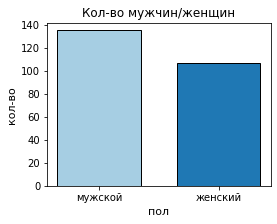

In [13]:
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure

plt.figure(figsize=(4,3))
# 1 - женский, 2 - мужсой
cats = ['мужской', 'женский']
cnts = [df['id'].loc[df['sex'] == 2].count(), df['id'].loc[df['sex'] == 1].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во мужчин/женщин')
plt.xlabel('пол', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()


### **4.2. Работа с признаком home_town**

In [14]:
df['home_town'].unique()

array(['Москва', nan, 'Тирасполь', 'Молдова-Тирасполь', 'Баку',
       'Tiraspol', 'Одесса', 'тирасполь', 'Джалиль', 'СПб',
       'Сергиев Посад', 'Зеленоград', 'Алматы', 'Тула', 'Чебоксары',
       'Н.Новгород', 'Бендеры', 'Ленинград', 'Куратово', 'Chicago',
       '———————————————— [ Мне] ———————————————— [ Мама] ———————————————— [ Сказала] ———————————————— [ Что] ———————————————— [ Я] ———————————————— [ Из] ———————————————— [ Животика]XD Языки: Русский',
       'Днепр', 'Иваново', 'караганда', 'Odesa', 'Кишинев', 'Kolkata',
       'Кишинёв', 'Атырау', 'Сан Сити', 'душанбе', 'Астана', 'Махачкала',
       'Myhosransk', 'россия', 'Рыбница', 'Moscow', 'Королевская гавань',
       'Bangladesh', 'Байконур', 'izmailovka', 'Huế', 'Талас', 'Viet Nam',
       'Будапешт', 'Ташкент', 'Балканабад, Туркменистан'], dtype=object)

In [15]:
df["home_town"].isnull().sum()/df.shape[0]

0.5206611570247934

In [16]:
df.home_town.replace('nan', 'Другой', inplace=True)
df.home_town.replace('', 'Другой', inplace=True)
df.home_town.fillna('Другой', inplace=True)

for i in df.home_town:
    if '— ['.lower() in i.lower(): df.home_town.replace(i, 'Другой', inplace=True)
    elif 'СПб'.lower() in i.lower() or 'Ленинград'.lower() in i.lower(): df.home_town.replace(i, 'Санкт-Петербург', inplace=True)
    elif 'Moscow'.lower() in i.lower(): df.home_town.replace(i, 'Москва', inplace=True)
    elif 'Тирасполь'.lower() in i.lower() or 'Tiraspol'.lower() in i.lower() or 'Myhosransk'.lower() in i.lower(): df.home_town.replace(i, 'Тирасполь', inplace=True)
    elif 'Odesa'.lower() in i.lower(): df.home_town.replace(i, 'Одесса', inplace=True)
    elif 'Кишинев'.lower() in i.lower(): df.home_town.replace(i, 'Кишинёв', inplace=True)

df.sort_values(by=['home_town']).home_town.unique()

array(['Bangladesh', 'Chicago', 'Huế', 'Kolkata', 'Viet Nam',
       'izmailovka', 'Алматы', 'Астана', 'Атырау', 'Байконур', 'Баку',
       'Балканабад, Туркменистан', 'Бендеры', 'Будапешт', 'Джалиль',
       'Днепр', 'Другой', 'Зеленоград', 'Иваново', 'Кишинёв',
       'Королевская гавань', 'Куратово', 'Махачкала', 'Москва',
       'Н.Новгород', 'Одесса', 'Рыбница', 'Сан Сити', 'Санкт-Петербург',
       'Сергиев Посад', 'Талас', 'Ташкент', 'Тирасполь', 'Тула',
       'Чебоксары', 'душанбе', 'караганда', 'россия'], dtype=object)

### **4.3. Работа с признаком has_mobile**

In [17]:
df['has_mobile'].unique()

array([ 1., nan,  0.])

In [18]:
df['has_mobile'].value_counts(dropna=False)

1.0    218
0.0     14
NaN     10
Name: has_mobile, dtype: int64

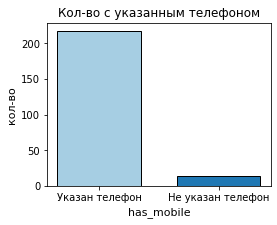

In [19]:
plt.figure(figsize=(4,3))
cats = ['Указан телефон', 'Не указан телефон']
cnts = [df['id'].loc[df['has_mobile'] == 1].count(), df['id'].loc[df['has_mobile'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во с указанным телефоном')
plt.xlabel('has_mobile', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [20]:
# Удаляем признака has_mobile, тк он указан у 219 из 242
df.drop(columns="has_mobile",inplace=True)

### **4.4. Работа с признаком followers_count**

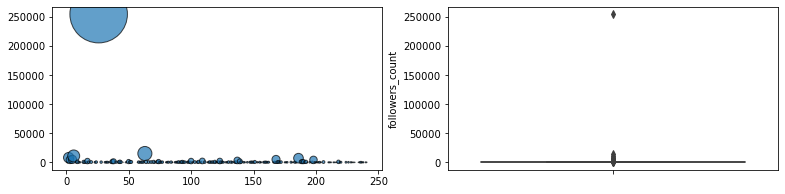

In [21]:
def plot_followers_plot():
  fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13,3))
  plt.subplot(1,2,1)
  # color='#FFC355',
  ax = plt.scatter([i for i in range(df.shape[0])], df.followers_count, cmap="Blues", alpha=0.7, edgecolors="black", linewidth=1, s=df.followers_count*0.013)
  plt.subplot(1,2,2)
  ax = sns.boxplot(y=df["followers_count"])
  plt.show()

plot_followers_plot()

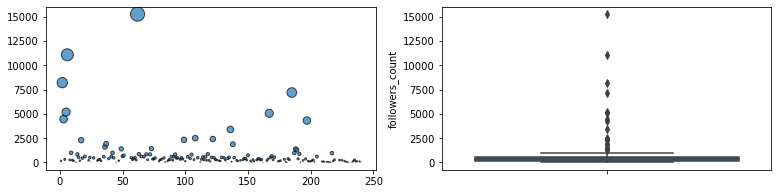

In [22]:
df = df.drop(df[df.followers_count > 200000].index)
plot_followers_plot()

### **4.5. Работа с признаком is_closed**

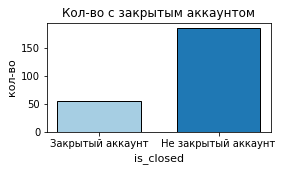

In [23]:
plt.figure(figsize=(4,2))
cats = ['Закрытый аккаунт', 'Не закрытый аккаунт']
cnts = [df['id'].loc[df['is_closed'] == 1].count(), df['id'].loc[df['is_closed'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во с закрытым аккаунтом')
plt.xlabel('is_closed', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [24]:
df['is_closed'].value_counts(dropna=False)

False    186
True      55
Name: is_closed, dtype: int64

### **4.6. Работа с признаком can_access_closed**

In [25]:
df['can_access_closed'].value_counts(dropna=False)

True    241
Name: can_access_closed, dtype: int64

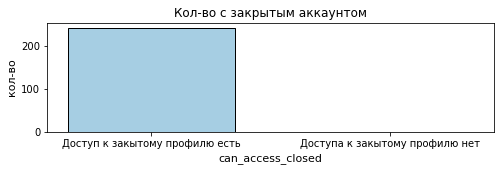

In [26]:
plt.figure(figsize=(8,2))
cats = ['Доступ к закытому профилю есть', 'Доступа к закытому профилю нет']
cnts = [df['id'].loc[df['can_access_closed'] == 1].count(), df['id'].loc[df['can_access_closed'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во с закрытым аккаунтом')
plt.xlabel('can_access_closed', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [27]:
# Удаляем признак can_access_closed, тк у всех значениие True
df.drop(columns="can_access_closed",inplace=True)

### **4.7. Работа с признаком can_see_audio**

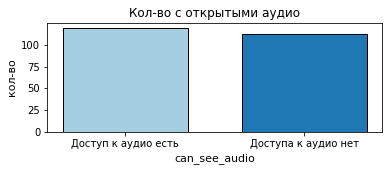

In [28]:
plt.figure(figsize=(6,2))
cats = ['Доступ к аудио есть', 'Доступа к аудио нет']
cnts = [df['id'].loc[df['can_see_audio'] == 1].count(), df['id'].loc[df['can_see_audio'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во с открытыми аудио')
plt.xlabel('can_see_audio', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [29]:
df['can_see_audio'].value_counts(dropna=False)

1.0    119
0.0    112
NaN     10
Name: can_see_audio, dtype: int64

### **4.8. Работа с признаком deactivated**

In [30]:
df['deactivated'].value_counts(dropna=False)

NaN        231
banned       7
deleted      3
Name: deactivated, dtype: int64

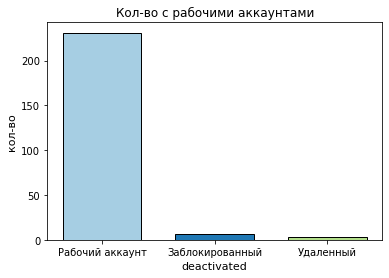

In [31]:
plt.figure(figsize=(6,4))
cats = ['Рабочий аккаунт', 'Заблокированный', 'Удаленный']
cnts = [df['id'].loc[df['deactivated'].isna()].count(), \
            df['id'].loc[df['deactivated'] == 'banned'].count(), df['id'].loc[df['deactivated'] == 'deleted'].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во с рабочими аккаунтами')
plt.xlabel('deactivated', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [32]:
# Удаление заблокированных и удаленных аккаунтов
df = df[df.deactivated.isin(['banned', 'deleted']) == False]

### **4.8. Работа с признаком can_see_all_posts**

In [33]:
df['can_see_all_posts'].value_counts(dropna=False)

1.0    174
0.0     57
Name: can_see_all_posts, dtype: int64

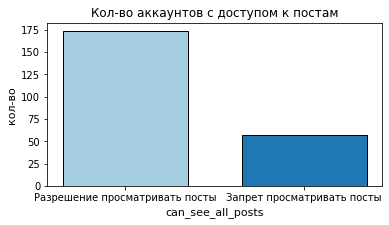

In [34]:
plt.figure(figsize=(6,3))
cats = ['Разрешение просматривать посты', 'Запрет просматривать посты']
cnts = [df['id'].loc[df['can_see_all_posts'] == 1].count(), df['id'].loc[df['can_see_all_posts'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с доступом к постам')
plt.xlabel('can_see_all_posts', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.9. Работа с признаком online**

In [35]:
df['online'].value_counts(dropna=False)

0    218
1     13
Name: online, dtype: int64

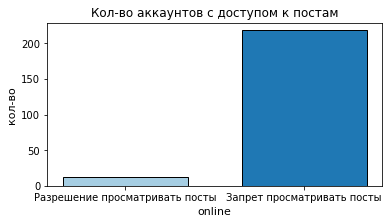

In [36]:
plt.figure(figsize=(6,3))
cats = ['Разрешение просматривать посты', 'Запрет просматривать посты']
cnts = [df['id'].loc[df['online'] == 1].count(), df['id'].loc[df['online'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с доступом к постам')
plt.xlabel('online', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [37]:
# Удаляем признак online, тк у 221 аккаунта запрет на просмотр постов
df.drop(columns="online",inplace=True)

### **4.11. Работа с признаком can_post**

In [38]:
df.columns

Index(['id', 'nickname', 'city', 'country', 'has_photo', 'can_post',
       'can_see_all_posts', 'can_see_audio', 'wall_default',
       'can_write_private_message', 'mobile_phone', 'home_phone', 'site',
       'status', 'common_count', 'occupation', 'home_town', 'relation',
       'personal', 'universities', 'schools', 'sex', 'first_name', 'last_name',
       'is_closed', 'bdate', 'followers_count', 'online_mobile', 'online_app',
       'deactivated', 'relation_partner', 'groups', 'subscriptions'],
      dtype='object')

In [39]:
df['can_post'].value_counts(dropna=False)

1    136
0     95
Name: can_post, dtype: int64

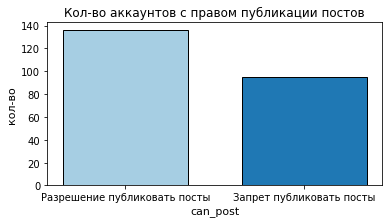

In [40]:
plt.figure(figsize=(6,3))
cats = ['Разрешение публиковать посты', 'Запрет публиковать посты']
cnts = [df['id'].loc[df['can_post'] == 1].count(), df['id'].loc[df['can_post'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с правом публикации постов')
plt.xlabel('can_post', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.12. Работа с признаком can_write_private_message**

In [41]:
df['can_write_private_message'].value_counts(dropna=False)

1    230
0      1
Name: can_write_private_message, dtype: int64

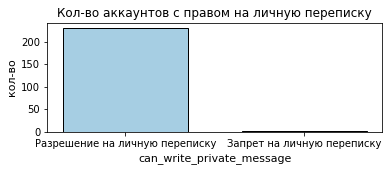

In [42]:
plt.figure(figsize=(6,2))
cats = ['Разрешение на личную переписку', 'Запрет на личную переписку']
cnts = [df['id'].loc[df['can_write_private_message'] == 1].count(), df['id'].loc[df['can_write_private_message'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с правом на личную переписку')
plt.xlabel('can_write_private_message', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [43]:
# Удаляем признак can_write_private_message, тк у 231 аккаунта разрешение на личную переписку
df.drop(columns="can_write_private_message",inplace=True)

### **4.14. Работа с признаком status**

In [44]:
print(df.status.unique(), sep = ' ')

['Новороссия и Россия празднуют признание и договоры о дружбе!!! Ура!!!!!!'
 nan
 '🎸 Играешь на гитаре и хочешь зарабатывать на любимом деле? Спроси меня КАК ;)'
 'Самая великая победа — победа над своим негативным мышлением. © Сократ'
 'Художник' 'Никогда не поздно выбрать Любовь'
 'Одни сидят на трубах, а другим нужны деньги...'
 'ʟᴜғᴛsᴄʜʟᴏss ✨/ ᴷ ᴀｌｓᴀ ʀｉᴷ ᴀｎｎｉｔ'
 'First I bang the drum, then I bang your mum' 'Я куплю много денег'
 'tg: @voyakin' '🦋'
 'Не хотел видеть половину из того, что видел, я не видел половины из того, что бы хотел увидеть'
 'nobody can drag me down' 'Ваши понты - для нас обычное дело' 'tanka__k'
 'Цель жизни макнуть пакетик в Тихий океан' 'Viva La Vida' 'coco jamboo'
 '🍄' 'паркур' '😊' 'Need some more!' '3,14159265358979323846' 'я счастлива'
 '🤫' '🖤' 'Хочу спать...и лето' 'I muri sono nella mente'
 "Don't set yourself on fire to keep others warm🔥"
 'держусь за эвкалипт как коала🌿🐨'
 'все проблемы из-за того , что просто так болтаешь'
 'Счастье есть🥰\n\nМой теле

In [45]:
# Делаем категориальный признак
df['status_f'] = np.where(df['status'].isna() == False, 1, 0)

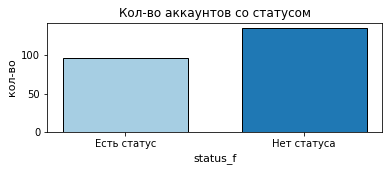

In [46]:
plt.figure(figsize=(6,2))
cats = ['Есть статус', 'Нет статуса']
cnts = [df['id'].loc[df['status_f'] == 1].count(), df['id'].loc[df['status_f'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов со статусом')
plt.xlabel('status_f', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.17. Работа с признаком has_photo**

In [47]:
df['has_photo'].value_counts(dropna=False)

1    213
0     18
Name: has_photo, dtype: int64

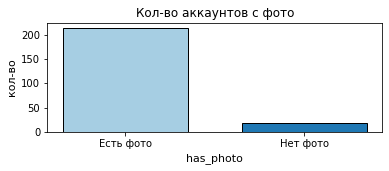

In [48]:
plt.figure(figsize=(6,2))
cats = ['Есть фото', 'Нет фото']
cnts = [df['id'].loc[df['has_photo'] == 1].count(), df['id'].loc[df['has_photo'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с фото')
plt.xlabel('has_photo', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.18. Работа с признаком site**

In [49]:
# Делаем категориальный признак
df['site_f'] = np.where(df['site'].isna() == False, 1, 0)

In [50]:
df['site_f'].value_counts(dropna=False)

0    203
1     28
Name: site_f, dtype: int64

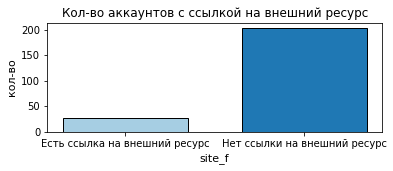

In [51]:
plt.figure(figsize=(6,2))
cats = ['Есть ссылка на внешний ресурс', 'Нет ссылки на внешний ресурс']
cnts = [df['id'].loc[df['site_f'] == 1].count(), df['id'].loc[df['site_f'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с ссылкой на внешний ресурс')
plt.xlabel('site_f', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.19. Работа с признаком wall_default**

In [52]:
# Делаем категориальный признак
df['wall_default_f'] = np.where(df['wall_default'] == 'all', 1, 0)

In [53]:
df['wall_default'].value_counts(dropna=False)

all      207
owner     24
Name: wall_default, dtype: int64

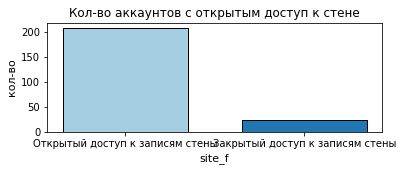

In [54]:
plt.figure(figsize=(6,2))
cats = ['Открытый доступ к записям стены', 'Закрытый доступ к записям стены']
cnts = [df['id'].loc[df['wall_default_f'] == 1].count(), df['id'].loc[df['wall_default_f'] == 0].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Кол-во аккаунтов с открытым доступ к стене')
plt.xlabel('site_f', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

### **4.20. Работа с признаком counters** (albums, audios, friends, photos, videos)

In [55]:
# df.counters[0]

In [56]:
# import warnings
# from pandas.core.common import SettingWithCopyWarning
# warnings.simplefilter(action="ignore", category=SettingWithCopyWarning)

# df['albums'] = 0
# df['audios'] = 0
# df['friends'] = 0
# df['photos'] = 0
# df['videos'] = 0

# m = 0
# for i in df.counters:
#   d = eval(i)
#   df['albums'][m] = d['albums']
#   df['audios'][m] = d['audios']
#   df['friends'][m] = d['friends']
#   df['photos'][m] = d['photos']
#   df['videos'][m] = d['videos']
#   m += 1

In [57]:
# sns.pairplot(data=df[['albums', 'audios', 'friends', 'photos', 'videos', 'followers_count', 'common_count']])

#### **4.20.1. Удаление выбросов**

In [58]:
# columns = ['albums', 'audios', 'friends', 'photos', 'videos', 'followers_count', 'common_count']

In [59]:
# for i in columns:
#   Q3 = np.quantile(df[i], 0.9)
#   Q1 = np.quantile(df[i], 0.1)
#   TIQR = 3 * (Q3 - Q1)
#   df = df.drop(df[df[i] > (Q3 + TIQR)].index)
#   df = df.drop(df[df[i] < (Q1 - TIQR)].index)

In [60]:
# df.shape

In [61]:
# df = df.reset_index()

In [62]:
# sns.pairplot(data=df[['albums', 'audios', 'friends', 'photos', 'videos', 'followers_count', 'common_count']])

### **4.21. Работа с признаком bdate**

In [63]:
df["bdate_year"] = df["bdate"]
df["bdate_year"].str.split(".").str.len().value_counts(dropna=False)
df.loc[df["bdate_year"].str.split(".").str.len()<3,"bdate_year"]=None
df["bdate_year"]=df["bdate_year"].str.extract("(.{4})$")
df["bdate_year"].unique()

array([nan, '1982', '1980', '1994', '1992', '1998', '1997', '1999',
       '2000', '1962', '2001', '2003', '2008', '1996', '1956', '1969'],
      dtype=object)

<AxesSubplot:>

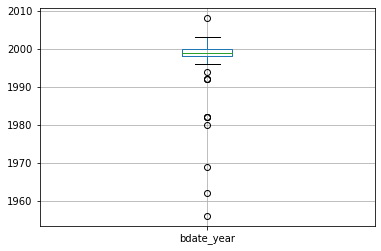

In [64]:
df["bdate_year"]=df["bdate_year"].astype(float).astype("Int64")
df.boxplot("bdate_year")

<AxesSubplot:>

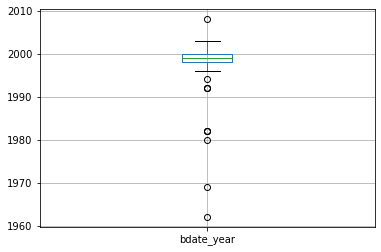

In [65]:
df = df.drop(df[df.bdate_year < 1960].index)
df.boxplot("bdate_year")

In [169]:
df["age"]=2023-df["bdate_year"]
df["age"].isnull().sum()/df.shape[0]
df["age"].fillna(0,inplace=True)
df.head(1)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level,age
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,1,2,0,0,0,5,0


In [66]:
df.columns

Index(['id', 'nickname', 'city', 'country', 'has_photo', 'can_post',
       'can_see_all_posts', 'can_see_audio', 'wall_default', 'mobile_phone',
       'home_phone', 'site', 'status', 'common_count', 'occupation',
       'home_town', 'relation', 'personal', 'universities', 'schools', 'sex',
       'first_name', 'last_name', 'is_closed', 'bdate', 'followers_count',
       'online_mobile', 'online_app', 'deactivated', 'relation_partner',
       'groups', 'subscriptions', 'status_f', 'site_f', 'wall_default_f',
       'bdate_year'],
      dtype='object')

### **4.22. Работа с признаком country**

In [67]:
df["country"].unique()

array(["{'id': 1, 'title': 'Россия'}", "{'id': 15, 'title': 'Молдова'}",
       nan, "{'id': 160, 'title': 'Польша'}",
       "{'id': 11, 'title': 'Кыргызстан'}",
       "{'id': 4, 'title': 'Казахстан'}", "{'id': 9, 'title': 'США'}",
       "{'id': 65, 'title': 'Германия'}", "{'id': 2, 'title': 'Украина'}",
       "{'id': 217, 'title': 'Швейцария'}",
       "{'id': 39, 'title': 'Болгария'}",
       "{'id': 209, 'title': 'Франция'}",
       "{'id': 16, 'title': 'Таджикистан'}",
       "{'id': 182, 'title': 'Сингапур'}", "{'id': 22, 'title': 'Алжир'}",
       "{'id': 30, 'title': 'Афганистан'}",
       "{'id': 55, 'title': 'Вьетнам'}", "{'id': 6, 'title': 'Армения'}"],
      dtype=object)

In [68]:
import ast
ast.literal_eval("{'muffin' : 'lolz', 'foo' : 'kitty'}")
def calc_country(cntr):
    if cntr is not np.nan:
        cntr_dict = ast.literal_eval(cntr)
        cntr_id = (cntr_dict['id'])
        cntr_name = (cntr_dict['title'])
    else:
        cntr_name = 'Неизвестно'
        cntr_id = -1
    res = [cntr_name, int(cntr_id)]
    return pd.Series(res)

df[["country_name", "country_id"]] = df.apply(lambda x: calc_country(x['country']), axis = 1)
df[["country_name", 'country_id']].head(3)

,country_name,country_id
0,Россия,1
1,Россия,1
2,Россия,1


<AxesSubplot:xlabel='count', ylabel='country_name'>

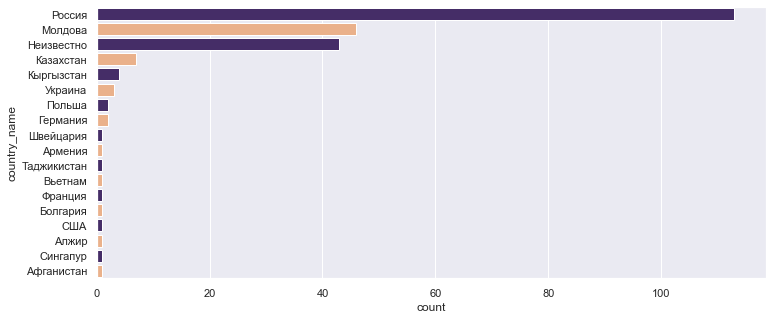

In [69]:
sns.set(rc={'figure.figsize':(12,5)})
sns.countplot(data = df, y="country_name", order=df['country_name'].value_counts().index, palette=['#432371',"#FAAE7B"], )

In [124]:
df.loc[df['country_name'] == 0, 'country_name'] = 'Неизвестно'
df.country_name.unique()

array(['Россия', 'Молдова', 'Неизвестно', 'Польша', 'Кыргызстан',
       'Казахстан', 'США', 'Германия', 'Украина', 'Швейцария', 'Болгария',
       'Франция', 'Таджикистан', 'Сингапур', 'Алжир', 'Афганистан',
       'Вьетнам', 'Армения'], dtype=object)

### **4.23. Работа с признаком occupation**

In [70]:
df.occupation.unique()

array(["{'id': 250, 'name': 'МГТУ им. Баумана', 'type': 'university', 'country_id': 1, 'city_id': 1}",
       "{'id': 262, 'name': 'МГУП (природообустройства)', 'type': 'university', 'graduate_year': 2005, 'country_id': 1, 'city_id': 1}",
       "{'id': 253, 'name': 'МИИГАиК', 'type': 'university', 'graduate_year': 2002, 'country_id': 1, 'city_id': 1}",
       nan,
       "{'id': 1298, 'name': 'ПГУ им. Шевченко', 'type': 'university', 'graduate_year': 2004, 'country_id': 15, 'city_id': 374}",
       "{'id': 1298, 'name': 'ПГУ им. Шевченко', 'type': 'university', 'graduate_year': 2016, 'country_id': 15, 'city_id': 374}",
       "{'id': 218179472, 'name': 'Emma Reznikova', 'type': 'work'}",
       "{'id': 226481, 'name': 'Гуманитарно-математическая гимназия (Gimnaziul umanist-matematic)', 'type': 'school', 'country_id': 15, 'city_id': 374}",
       "{'id': 86456, 'name': 'МИПП (ТФ)', 'type': 'university', 'graduate_year': 2013, 'country_id': 15, 'city_id': 374}",
       "{'id': 86456, 'n

In [71]:
df['occupation'].fillna("{'id': 11111, 'name': 'Не указано'}", inplace = True)

In [72]:
df['work'] = "Не указано"

m = 0
for i in df.occupation:
  d = eval(i)
  df['work'][m] = d['name']
  m += 1

c:\Users\comps\AppData\Local\Programs\Python\Python37\lib\site-packages\ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
c:\Users\comps\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\core\indexing.py:1637: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_block(indexer, value, name)


In [126]:
df.loc[df['work'] == 0, 'work'] = 'Не указано'
df.work.unique()

array(['МГТУ им. Баумана', 'МГУП (природообустройства)', 'МИИГАиК',
       'Не указано', 'ПГУ им. Шевченко', 'Emma Reznikova',
       'Гуманитарно-математическая гимназия (Gimnaziul umanist-matematic)',
       'МИПП (ТФ)', 'МГТУ им. Н. Э. Баумана', 'НУ «ЛП»',
       'Короче говоря, Игл', 'МАТИ - РГТУ им. К. Э. Циолковского',
       'МГИМО МИД России', 'ВГУ', 'Комитет Внешних Связей',
       'СПбГУПТД (бывш. СПГУТД)', 'InfoTeCS Team', 'НИУ ВШЭ (ГУ-ВШЭ)',
       'КРОК', 'жизнь в фотографиях',
       'Московский политехнический университет', 'домашнее хозяйство',
       'Банк ВТБ', 'Яндекс для разработчиков',
       'Национальный музыкально-драматический театр Коми',
       'Российский футбольный союз | РФС',
       'БГТУ «Военмех» им. Д. Ф. Устинова', '24Hours Dance Team',
       'Финансовый университет при Правительстве РФ (бывш. ФА при Правительстве РФ)',
       'РНИМУ (бывш. РГМУ) им. Н. И. Пирогова', 'ИвГУ\r\n',
       'СберМегаМаркет',
       'Universitatea de Stat de Medicină şi Fa

### **4.24. Работа с признаком city**

In [74]:
df['city'].fillna("{'id': 11111, 'title': 'Другой'}", inplace = True)

In [75]:
df.city.unique()

array(["{'id': 1, 'title': 'Москва'}",
       "{'id': 158, 'title': 'Челябинск'}",
       "{'id': 374, 'title': 'Тирасполь'}",
       "{'id': 11111, 'title': 'Другой'}",
       "{'id': 204, 'title': 'Бишкек'}",
       "{'id': 1710959, 'title': 'Кишинев'}",
       "{'id': 2, 'title': 'Санкт-Петербург'}",
       "{'id': 183, 'title': 'Алматы'}",
       "{'id': 149, 'title': 'Ульяновск'}",
       "{'id': 95, 'title': 'Нижний Новгород'}",
       "{'id': 1037015, 'title': 'Куратово'}",
       "{'id': 1017, 'title': 'Chicago'}",
       "{'id': 1951986, 'title': 'München'}",
       "{'id': 15419, 'title': 'Молочные Дворы'}",
       "{'id': 650, 'title': 'Днепр (Днепропетровск)'}",
       "{'id': 1109771, 'title': 'Постол (деревня)'}",
       "{'id': 2202278, 'title': 'Kraków'}",
       "{'id': 284, 'title': 'Караганда'}",
       "{'id': 314, 'title': 'Киев'}", "{'id': 703, 'title': 'Zürich'}",
       "{'id': 1913178, 'title': 'Sofia'}",
       "{'id': 2134, 'title': 'Montpellier'}",
       "{

In [76]:
df['city_new'] = "Другой"
m = 0
for i in df.city:
  d = eval(i)
  df['city_new'][m] = d['title']
  m += 1

c:\Users\comps\AppData\Local\Programs\Python\Python37\lib\site-packages\ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """


In [120]:
df.loc[df['city_new'] == 0, 'city_new'] = 'Другой'
df.city_new.unique()

array(['Москва', 'Челябинск', 'Тирасполь', 'Другой', 'Бишкек', 'Кишинев',
       'Санкт-Петербург', 'Алматы', 'Ульяновск', 'Куратово', 'Chicago',
       'München', 'Молочные Дворы', 'Днепр (Днепропетровск)',
       'Постол (деревня)', 'Kraków', 'Караганда', 'Киев', 'Zürich',
       'Sofia', 'Montpellier', 'Одесса', 'Комрат', 'Душанбе', 'Singapore',
       'Жуковский', 'Alger', 'Бендеры', 'Шымкент', 'Nürnberg',
       'Mazār-e Sharīf', 'Талас', 'Ереван', 'Долгопрудный'], dtype=object)

### **4.25. Работа с personal**

In [77]:
pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval))).head(2)

,langs,langs_full,religion,alcohol,inspired_by,life_main,people_main,smoking,political,religion_id
0,[Русский],"[{'id': 0, 'native_name': 'Русский'}]",Blackmore is god!,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,0.0,,0.0,0.0,0.0,NaN,NaN


In [78]:
df["alcohol"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["alcohol"]
df["inspired_by"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["inspired_by"]
df["langs"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["langs"]
df["life_main"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["life_main"]
df["people_main"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["people_main"]
df["political"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["political"]
df["smoking"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["smoking"]
df["religion"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["religion"]
df["religion_id"]=pd.DataFrame(list(df['personal'].fillna("{}").replace("[]","{}").apply(ast.literal_eval)))["religion_id"]
# df=df.drop(columns=["personal"])
df.head(3)

,id,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,...,city_new,alcohol,inspired_by,langs,life_main,people_main,political,smoking,religion,religion_id
0,802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1.0,1.0,all,NaN,...,Москва,NaN,NaN,[Русский],NaN,NaN,NaN,NaN,Blackmore is god!,NaN
1,1034007,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1,1.0,1.0,all,8 (926) 521-61-97,...,Москва,0.0,,NaN,0.0,0.0,NaN,0.0,NaN,NaN
2,1178812,NaN,"{'id': 158, 'title': 'Челябинск'}","{'id': 1, 'title': 'Россия'}",1,1,1.0,1.0,all,NaN,...,Челябинск,0.0,,[Русский],0.0,0.0,8.0,0.0,NaN,NaN


##### **4.25.1. Работа с alcohol**

In [79]:
df['alcohol'].value_counts(dropna=False)

0.0    118
NaN     85
2.0      7
4.0      7
1.0      5
3.0      5
5.0      3
Name: alcohol, dtype: int64

In [178]:
df["alcohol"]=df["alcohol"].fillna(round(df["alcohol"].mean()))
df.head(2)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level,age
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,1,2,0,0,0,5,0
1034007,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1,1,1,all,8 (926) 521-61-97,NaN,...,0,0,0,1,0,0,0,0,5,41


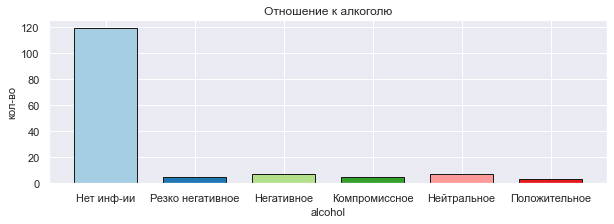

In [81]:
# 1 - Резко негативное
# 2 - Негативное
# 3 - Компромиссное
# 4 - Нейтральное
# 5 - Положительное

plt.figure(figsize=(10, 3))
cats = ['Нет инф-ии', 'Резко негативное', 'Негативное', 'Компромиссное', 'Нейтральное', 'Положительное']
cnts = [df['id'].loc[df['alcohol'] == 0].count(), df['id'].loc[df['alcohol'] == 1].count(), \
        df['id'].loc[df['alcohol'] == 2].count(), df['id'].loc[df['alcohol'] == 3].count(), \
        df['id'].loc[df['alcohol'] == 4].count(), df['id'].loc[df['alcohol'] == 5].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Отношение к алкоголю')
plt.xlabel('alcohol', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

In [179]:
df['alcohol'].value_counts(dropna=False)

0.0    119
1.0     89
2.0      7
4.0      7
3.0      5
5.0      3
Name: alcohol, dtype: int64

##### **4.25.2. Работа с langs**

In [82]:
df["langs"].astype(str).value_counts()

nan                                                               112
['Русский']                                                        66
['Русский', 'English']                                             15
['Русский', 'English', 'Deutsch']                                   5
['English']                                                         3
['Русский', 'English', 'Українська']                                3
['English', 'Русский']                                              1
['Қазақша', 'Русский']                                              1
['Русский', 'Коми кыв']                                             1
['English', 'Русский', 'Tiếng Việt', '汉语']                          1
['English', 'Русский', 'Polski']                                    1
['Русский', 'Українська', 'English', 'Polski']                      1
['Русский', 'Հայերեն', 'English', 'ქართული']                        1
['Русский', 'Українська', 'English']                                1
['Moldovenească']   

In [83]:
df=df.drop(columns=["langs"])

##### **4.25.3. Работа с life_main**

In [84]:
df["life_main"]=df["life_main"].replace(0,None).replace({1:"Семья и дети",2:"Карьера и деньги",3:"Развлечение и отдых",
                                           4:"Наука и исследования",5:"Совершенствование мира",
                                           6:"Саморазвитие",7:"Красота и искусство",8:"Слава и влияние"})
df["life_main"]

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
237    NaN
238    NaN
239    NaN
240    NaN
241    NaN
Name: life_main, Length: 230, dtype: object

In [85]:
df['life_main'].value_counts(dropna=False)

NaN                       150
Саморазвитие               23
Семья и дети               19
Красота и искусство        14
Совершенствование мира      8
Развлечение и отдых         7
Карьера и деньги            5
Наука и исследования        4
Name: life_main, dtype: int64

##### **4.25.4. Работа с people_main**

In [86]:
df["people_main"]=df["people_main"].replace(0,None).replace({1:"Ум и креативность",2:"Доброта и честность",3:"Красота и здоровье",
                                           4:"Власть и богатство",5:"Смелость и упорство",
                                           6:"Юмор и жизнелюбие"})
df["people_main"]

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
      ... 
237    NaN
238    NaN
239    NaN
240    NaN
241    NaN
Name: people_main, Length: 230, dtype: object

In [87]:
df['people_main'].value_counts(dropna=False)

NaN                    150
Доброта и честность     36
Юмор и жизнелюбие       22
Смелость и упорство     12
Ум и креативность        6
Красота и здоровье       4
Name: people_main, dtype: int64

##### **4.25.5. Работа с political**

In [88]:
df["political"]=df["political"].replace(0,None).replace({1:"Коммунизм",2:"Социализм",3:"Аполитическая",
                                           4:"Либерализм",5:"Консерватизм",6:"Монархия",7:"Ультраконсерватизм",8:"Аполитическая",
                                           9:"Либертарианство"})
df["political"]

0                NaN
1                NaN
2      Аполитическая
3                NaN
4                NaN
           ...      
237              NaN
238              NaN
239              NaN
240              NaN
241              NaN
Name: political, Length: 230, dtype: object

In [89]:
df['political'].value_counts(dropna=False)

NaN                   211
Аполитическая          12
Монархия                2
Либерализм              2
Консерватизм            1
Ультраконсерватизм      1
Либертарианство         1
Name: political, dtype: int64

##### **4.25.6. Работа с smoking**

In [90]:
df['smoking'].value_counts(dropna=False)

0.0    103
NaN     85
1.0     14
4.0     12
2.0      8
3.0      6
5.0      2
Name: smoking, dtype: int64

In [180]:
df["smoking"]=df["smoking"].fillna(round(df["smoking"].mean()))
df.head(2)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level,age
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,1,2,0,0,0,5,0
1034007,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1,1,1,all,8 (926) 521-61-97,NaN,...,0,0,0,1,0,0,0,0,5,41


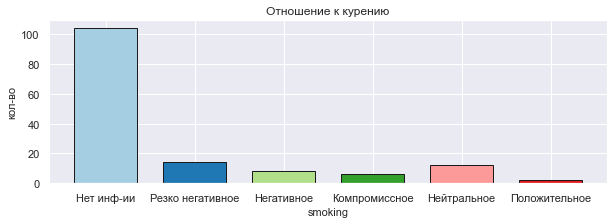

In [92]:
# 1 - Резко негативное
# 2 - Негативное
# 3 - Компромиссное
# 4 - Нейтральное
# 5 - Положительное

plt.figure(figsize=(10, 3))
cats = ['Нет инф-ии', 'Резко негативное', 'Негативное', 'Компромиссное', 'Нейтральное', 'Положительное']
cnts = [df['id'].loc[df['smoking'] == 0].count(), df['id'].loc[df['smoking'] == 1].count(), \
        df['id'].loc[df['smoking'] == 2].count(), df['id'].loc[df['smoking'] == 3].count(), \
        df['id'].loc[df['smoking'] == 4].count(), df['id'].loc[df['smoking'] == 5].count()]
col_map = plt.get_cmap('Paired')
plt.bar(cats, cnts, width=0.7, color=col_map.colors, edgecolor='k', linewidth=1)
plt.title('Отношение к курению')
plt.xlabel('smoking', fontsize=11)
plt.ylabel('кол-во', fontsize=11)
plt.show()

##### **4.25.7. Работа с religion**

In [93]:
df=df.drop(columns=["religion_id"])

In [110]:
df['religion'].value_counts(dropna=False)

                   217
православ            6
светск гуманизм      3
атеизм               2
пастафарианств       1
атеист               1
Name: religion, dtype: int64

### **4.26. Работа с groups, subscriptions**

In [107]:
df[['id', 'nickname', 'country_name', 'city_new', 'work', 'groups', 'subscriptions', 'occupation']].head(3)

,id,nickname,country_name,city_new,work,groups,subscriptions,occupation
0,802442,NaN,Россия,Москва,МГТУ им. Баумана,"[{""id"": 74962618, ""description"": ""\u0417\u0434...","[{""id"": 74962618, ""description"": ""\u0417\u0434...","{'id': 250, 'name': 'МГТУ им. Баумана', 'type'..."
1,1034007,NaN,Россия,Москва,МГУП (природообустройства),"[{""id"": 180221284, ""description"": """", ""activit...","[{""id"": 180221284, ""description"": """", ""activit...","{'id': 262, 'name': 'МГУП (природообустройства..."
2,1178812,NaN,Россия,Челябинск,МИИГАиК,"[{""id"": 201551590, ""description"": ""\u041a\u043...","[{""id"": 67580761, ""description"": ""\u041d\u0430...","{'id': 253, 'name': 'МИИГАиК', 'type': 'univer..."


In [96]:
from ftfy import fix_text
import json

t = pd.DataFrame(json.loads( fix_text(df["subscriptions"][12]), strict=False ))  #subscriptions  #groups
t[t["type"] == "page"]
t.head(3)

,id,description,activity,name,screen_name,is_closed,type,is_admin,is_member,is_advertiser,photo_50,photo_100,photo_200
0,206962345,"Заповедный хутор - место обитания лосей, волка...","Национальный парк, заповедник","Заповедный хутор ""Белый лось"" 8-916-346-99-11",wildwildrussian,0,page,0,0,0,https://sun1-14.userapi.com/s/v1/ig2/_LWrhmJNa...,https://sun1-14.userapi.com/s/v1/ig2/J_ownT08n...,https://sun1-14.userapi.com/s/v1/ig2/wDh21VpQp...
1,34215577,"Мы публикуем только то, что присылают наши чит...",Юмор,Подслушано – Здесь говорят о тебе,overhear,0,page,0,1,0,https://sun1-96.userapi.com/s/v1/ig2/cuUvTtCV1...,https://sun1-96.userapi.com/s/v1/ig2/iu7ProwBO...,https://sun1-96.userapi.com/s/v1/ig2/j4_Sk0CVm...
2,24923174,Официальная группа производственного комплекса...,"Производство, промышленность",ПК «Салют» АО «ОДК»,npcsalut,0,page,0,0,0,https://sun1-86.userapi.com/s/v1/ig2/S7b5APQ4b...,https://sun1-86.userapi.com/s/v1/ig2/zhn4Y8AK-...,https://sun1-86.userapi.com/s/v1/ig2/WzUiuCgFY...


In [97]:
import re
# k=0
def f(s):
  # global k
  # print(k)
  # k+=1
  if s == "[]":
    return ""
  try:
    t=pd.DataFrame(json.loads( fix_text(s) ))
  except:
    return ""
  try:
    t["name"]=t["name"].fillna("").apply(lambda x: " ".join(map(lambda x:x.lower(),re.findall(r"(\w*[ЦцКкНнГгШшЩщЗзХхФфВвПпРрЛлДдЖжЧчСсМмТтБб])[УуЕеЫыАаОоЭэЯяИиЬьЮюЯяЙй]*",x))))#,re.findall(r"\W([А-Яа-яЁё]+[ЦцКкНнГгШшЩщЗзХхФфВвПпРрЛлДдЖжЧчСсМмТтБб])[УуЕеЫыАаОоЭэЯяИиЬьЮю]\W",x))))
    t["description"]=t["description"].fillna("").apply(lambda x: " ".join(map(lambda x:x.lower(),re.findall(r"(\w*[ЦцКкНнГгШшЩщЗзХхФфВвПпРрЛлДдЖжЧчСсМмТтБб])[УуЕеЫыАаОоЭэЯяИиЬьЮюЯяЙй]*",x))))#[\w']+
    t["activity"]=t["activity"].fillna("").apply(lambda x: " ".join(map(lambda x:x.lower(),re.findall(r"(\w*[ЦцКкНнГгШшЩщЗзХхФфВвПпРрЛлДдЖжЧчСсМмТтБб])[УуЕеЫыАаОоЭэЯяИиЬьЮюЯяЙй]*",x))))
    t["rez"]=t["name"]+" "+t["description"]+" "+t["activity"]+" "
    t["rez"]=t["name"]
  except:
    return ""
  return t["rez"].sum().strip()

df["groups_"]=df["groups"].fillna("[]").apply(f)
df["subscriptions_"]=df["subscriptions"].fillna("[]").apply(f)
# df["subscriptions_"].unique()

array(['городск сказкстуденческ исторвесёл социопатпрогулк сквоз вектерр пратчетт цитат книг обсужденэтимолог н кажд денкотополисх миядзак лучш анимстар москвкотокаф котиссим москвфилологическ деввс скандинавсин кот рин зенюк',
       'тв тур агенткинокайф лучш фильмтц хан москвтанц дл дет в долгопрудном',
       'кбинтересн планет путешеств туризмтипичн новосибирсксделан человекомженск мыслнаук техникольг вайнер личн блогтипичн нижн новгородкотизмблошктипичн творческмысл стасмхкблаготворительн проект дар добр воткинскгородск сказктаверн сумеречн кот фэнтез фантастик',
       'академ наставниковзаписк старог инфоцыганворкаут казан официальн группананд ален специалист п финансаминтернет маркетингпросветленпетр осипов метаморфозаккорд песн вс делзаписк миллионерпсихолог джокерзож сам себ тренерандр шаккар блог жизн мотивац успехкниг музык ладамиррмотивац спарт антон бритвдум богатандр парабеллумфилософ планетпутешеств туризмиз куед блог аяз шабутдинов',
       'русск дом в кишинёврусск д

In [102]:
# df.loc[(df["groups_"] != '') & (df["subscriptions_"] != "")]

In [156]:
def f(x):
  return " ".join(map(lambda x:x.lower(), re.findall(r"(\w*[ЦцКкНнГгШшЩщЗзХхФфВвПпРрЛлДдЖжЧчСсМмТтБб])[УуЕеЫыАаОоЭэЯяИиЬьЮюЯяЙй]*",x)))
df["inspired_by"]=df["inspired_by"].fillna("").apply(f)
df["life_main"]=df["life_main"].fillna("").apply(f)
df["people_main"]=df["people_main"].fillna("").apply(f)
df["political"]=df["political"].fillna("").apply(f)
df["religion"]=df["religion"].fillna("").apply(f)
df["status"]=df["status"].fillna("").apply(f)
df.head(1)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Садовод,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,0,1,2,0,0,0,5


In [157]:
df["all_text_info"]=df["groups_"]+" "+df["subscriptions_"]+" "+\
    df["life_main"]+" "+df["people_main"]+" "+df["political"]+" "+df["religion"]+" "+df["inspired_by"]+" "+\
    df["city_new"]+" "+df["work"]+" "+df["country_name"]+" "+df["status"]+" "

df['all_text_info'] = df['all_text_info'].str.lower()
df.head(1)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Садовод,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,0,1,2,0,0,0,5


In [163]:
txt=df["all_text_info"].sum()
m=txt.split(" ")
tdf=pd.Series(m)
# tdf

In [164]:
tdf=tdf.drop(tdf[tdf==""].index)
tdf=pd.DataFrame(tdf.value_counts()).reset_index().rename(columns={"index":"Слово",0:"Частота"})
tdf["Длина"]=tdf["Слово"].str.len()

In [190]:
# tdf=tdf[tdf["Длина"]>4]
# tdf.loc[tdf["Частота"] > 28]
tdf.loc[tdf["Частота"] > 20].to_csv("word_rate.csv", encoding='utf-8')

In [191]:
words=["студентов","баумана","одежд","приднестров","магазин","музык","россия","москв","фильм","новост"]
words

['студентов',
 'баумана',
 'одежд',
 'приднестров',
 'магазин',
 'музык',
 'россия',
 'москв',
 'фильм',
 'новост']

In [194]:
def ps(s):
    t=pd.Series(s.split(" "))
    t=t.drop(t[t==""].index)
    t=pd.DataFrame(t.value_counts()).reset_index().rename(columns={"index":"Слово", 0:"Частота"})
    words=["студентов","студент","баумана","бауман","бауманподслушан","садовод","одежд",
           "приднестров","тираспол","тирасполь","молдова","магазин","музык","россия","москв", "москва", "фильм","искусств",'культур','фотограф',"новост"]
    t=t.set_index("Слово").to_dict()["Частота"]
    m=[]
    words_dist=["студентов","баумана","одежд","приднестров","магазин","музык","россия","москв","фильм","новост"]
    for i in words_dist:
        # print((t.get(i, 0)))
        if i in ['студентов']:
            m.append(t.get('студентов', 0) + t.get('студент', 0))
        elif i in ["баумана"]:
            m.append(t.get('баумана', 0) + t.get('бауман', 0) + t.get("бауманподслушан", 0))
        elif i in ["одежд"]:
            m.append(t.get('садовод', 0) + t.get('одежд', 0))
        elif i in ["приднестров"]:
            m.append(t.get('приднестров', 0) + t.get('тираспол', 0) + t.get('тирасполь', 0) + t.get('молдова', 0))
        elif i in ["москв"]:
            m.append(t.get('москв', 0) + t.get('москва', 0))
        elif i in ["фильм"]:
            m.append(t.get('фильм', 0) + t.get('искусств', 0) + t.get('фотограф', 0) + t.get('культур', 0))
        else:
            m.append(t.get(i, 0))
    return pd.Series(m)

tt=df["all_text_info"].apply(ps)
for i,z in enumerate(["Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Россия","Москва","Фильмы","Новости"]):
  df[z]=tt[i]

In [195]:
df.head(2)

,nickname,city,country,has_photo,can_post,can_see_all_posts,can_see_audio,wall_default,mobile_phone,home_phone,...,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,Одежда,transparency_level,age
id,,,,,,,,,,,,,,,,,,,,,
802442,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,0,1,1,all,NaN,NaN,...,0,0,0,1,3,0,0,0,5,0
1034007,NaN,"{'id': 1, 'title': 'Москва'}","{'id': 1, 'title': 'Россия'}",1,1,1,1,all,8 (926) 521-61-97,NaN,...,0,0,0,1,1,0,0,0,5,41


### **4.27. Создание синтетических признаков transparency_level и media**

In [150]:
df['is_closed'] = df.is_closed.astype(int)
df['can_see_audio'] = df.can_see_audio.astype(int)
df['can_see_all_posts'] = df.can_see_all_posts.astype(int)
df['followers_count'] = df['followers_count'].fillna(0)
df['followers_count'] = df.followers_count.astype(int)
df['common_count'] = df.common_count.astype(int)
df['can_post'] = df.can_post.astype(int)
df['has_photo'] = df.has_photo.astype(int)
df['site_f'] = df.site_f.astype(int)
df['wall_default_f'] = df.wall_default_f.astype(int)

In [151]:
df['transparency_level'] = df.is_closed + df.can_see_audio + df.can_post + df.can_see_all_posts + df.has_photo + df.site_f + df.wall_default_f

In [153]:
# df['media'] = df.audios + df.videos + df.photos

In [ ]:
df10 = df[
             
             ['sex', 'first_name', 'last_name', 'relation', 'home_town', 'city_new', 'work',
               'friends', 'followers_count', 'common_count', 'transparency_level', 'media', 'albums']            
]

In [ ]:
df10.head()

In [170]:
df.columns

Index(['nickname', 'city', 'country', 'has_photo', 'can_post',
       'can_see_all_posts', 'can_see_audio', 'wall_default', 'mobile_phone',
       'home_phone', 'site', 'status', 'common_count', 'occupation',
       'home_town', 'relation', 'personal', 'universities', 'schools', 'sex',
       'first_name', 'last_name', 'is_closed', 'bdate', 'followers_count',
       'online_mobile', 'online_app', 'deactivated', 'relation_partner',
       'groups', 'subscriptions', 'status_f', 'site_f', 'wall_default_f',
       'bdate_year', 'country_name', 'country_id', 'work', 'city_new',
       'alcohol', 'inspired_by', 'life_main', 'people_main', 'political',
       'smoking', 'religion', 'groups_', 'subscriptions_', 'all_text_info',
       'Студенты', 'Бауманка', 'Садовод', 'Приднестровье', 'Магазин', 'Музыка',
       'Россия', 'Москва', 'Фильмы', 'Новости', 'Одежда', 'transparency_level',
       'age'],
      dtype='object')

## **5. Подготовка к кластеризации**

### **5.1. Выбор набора признаков**

In [262]:
df=df.set_index("id")
df.head(1)

KeyError: "None of ['id'] are in the columns"

In [296]:
df_clust =  df[  ['first_name', 'last_name', 'sex', 'age', 'common_count', 'followers_count', 
                'smoking',  'alcohol', 'transparency_level', 
               "Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Россия","Москва","Фильмы","Новости"] ]

In [297]:
df_clust[df_clust.isna().any(axis=1)]

,first_name,last_name,sex,age,common_count,followers_count,smoking,alcohol,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости
id,,,,,,,,,,,,,,,,,,,


In [298]:
df_clust.head(2)

,first_name,last_name,sex,age,common_count,followers_count,smoking,alcohol,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости
id,,,,,,,,,,,,,,,,,,,
802442,Лилия,Волкова,1,0,5,0,0.0,0.0,5,0,1,0,0,0,0,1,3,0,0
1034007,Александр,Игнатенко,2,41,7,163,0.0,0.0,5,0,0,0,0,0,0,1,1,0,0


In [299]:
import warnings
from pandas.core.common import SettingWithCopyWarning

warnings.simplefilter(action="ignore", category=SettingWithCopyWarning)

#  ["Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Россия","Москва","Фильмы","Новости"]:
m={}
for i in ["Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Москва","Фильмы","Новости"]:
    m[i]=round(df_clust[i]/(df_clust["Студенты"].fillna(0)+df_clust["Бауманка"].fillna(0)+df_clust["Одежда"].fillna(0)+df_clust["Приднестровье"].fillna(0)+
                      df_clust["Магазин"].fillna(0)+df_clust["Музыка"].fillna(0)+
                      df_clust["Москва"].fillna(0)+df_clust["Фильмы"].fillna(0)+df_clust["Новости"].fillna(0))*100)
    
for i in ["Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Москва","Фильмы","Новости"]:
    df_clust[i]=m[i]

In [300]:
df_clust.head(2)

,first_name,last_name,sex,age,common_count,followers_count,smoking,alcohol,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости
id,,,,,,,,,,,,,,,,,,,
802442,Лилия,Волкова,1,0,5,0,0.0,0.0,5,0.0,25.0,0.0,0.0,0.0,0.0,1,75.0,0.0,0.0
1034007,Александр,Игнатенко,2,41,7,163,0.0,0.0,5,0.0,0.0,0.0,0.0,0.0,0.0,1,100.0,0.0,0.0


In [301]:
df_clust=df_clust.drop(df_clust[df_clust.isna().any(axis=1)].index)

### **5.2. Тепловая карта числовых признаков**

In [302]:
df_clust.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 209 entries, 802442 to 697861287
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   first_name          209 non-null    object 
 1   last_name           209 non-null    object 
 2   sex                 209 non-null    int64  
 3   age                 209 non-null    Int64  
 4   common_count        209 non-null    int32  
 5   followers_count     209 non-null    int32  
 6   smoking             209 non-null    float64
 7   alcohol             209 non-null    float64
 8   transparency_level  209 non-null    int32  
 9   Студенты            209 non-null    float64
 10  Бауманка            209 non-null    float64
 11  Одежда              209 non-null    float64
 12  Приднестровье       209 non-null    float64
 13  Магазин             209 non-null    float64
 14  Музыка              209 non-null    float64
 15  Россия              209 non-null    int64  
 1

In [303]:
digit_feature_mask = (df_clust.dtypes==int) | (df_clust.dtypes==np.int64) | (df_clust.dtypes==float)
digit_cols = df_clust.columns[digit_feature_mask].tolist()
digit_cols

['sex',
 'common_count',
 'followers_count',
 'smoking',
 'alcohol',
 'transparency_level',
 'Студенты',
 'Бауманка',
 'Одежда',
 'Приднестровье',
 'Магазин',
 'Музыка',
 'Россия',
 'Москва',
 'Фильмы',
 'Новости']

In [304]:
df_digit = df_clust[digit_cols]

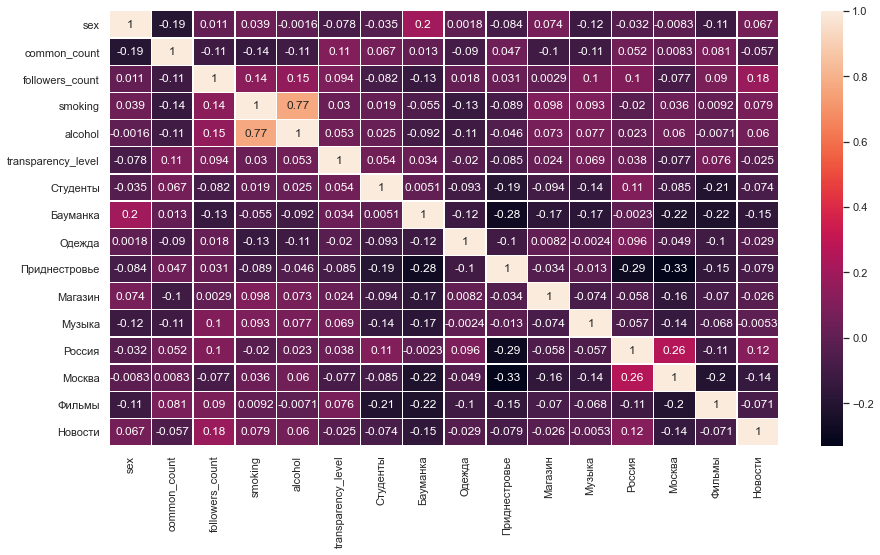

In [305]:
sns.heatmap(df_digit.corr(), annot=True, linewidths=0.3)
fig = plt.gcf()
fig.set_size_inches(15,8)

In [306]:
df_clust["bad_habits"] = df_clust["alcohol"] + df_clust["smoking"]
df_clust.head(2)

,first_name,last_name,sex,age,common_count,followers_count,smoking,alcohol,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,bad_habits
id,,,,,,,,,,,,,,,,,,,,
802442,Лилия,Волкова,1,0,5,0,0.0,0.0,5,0.0,25.0,0.0,0.0,0.0,0.0,1,75.0,0.0,0.0,0.0
1034007,Александр,Игнатенко,2,41,7,163,0.0,0.0,5,0.0,0.0,0.0,0.0,0.0,0.0,1,100.0,0.0,0.0,0.0


In [307]:
df_clust = df_clust.drop(columns=['alcohol', 'smoking'])
df_clust.head(2)

,first_name,last_name,sex,age,common_count,followers_count,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Россия,Москва,Фильмы,Новости,bad_habits
id,,,,,,,,,,,,,,,,,,
802442,Лилия,Волкова,1,0,5,0,5,0.0,25.0,0.0,0.0,0.0,0.0,1,75.0,0.0,0.0,0.0
1034007,Александр,Игнатенко,2,41,7,163,5,0.0,0.0,0.0,0.0,0.0,0.0,1,100.0,0.0,0.0,0.0


In [308]:
df_clust_old = df_clust.copy(deep=True)
df_clust = df_clust.drop(columns=['Россия'])
df_clust.head(2)

,first_name,last_name,sex,age,common_count,followers_count,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Москва,Фильмы,Новости,bad_habits
id,,,,,,,,,,,,,,,,,
802442,Лилия,Волкова,1,0,5,0,5,0.0,25.0,0.0,0.0,0.0,0.0,75.0,0.0,0.0,0.0
1034007,Александр,Игнатенко,2,41,7,163,5,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0


## **6. Создание конвейера для подбора лучшей модели**

In [309]:
old_df=df_clust.copy(deep=True)

In [310]:
df_clust.columns

Index(['first_name', 'last_name', 'sex', 'age', 'common_count',
       'followers_count', 'transparency_level', 'Студенты', 'Бауманка',
       'Одежда', 'Приднестровье', 'Магазин', 'Музыка', 'Москва', 'Фильмы',
       'Новости', 'bad_habits'],
      dtype='object')

In [311]:
df_clust=df_clust.drop(columns=['first_name', 'last_name', 'common_count',
       'followers_count'])
df_clust.head(2)

,sex,age,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Москва,Фильмы,Новости,bad_habits
id,,,,,,,,,,,,,
802442,1,0,5,0.0,25.0,0.0,0.0,0.0,0.0,75.0,0.0,0.0,0.0
1034007,2,41,5,0.0,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0


In [312]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler, RobustScaler, Normalizer

In [313]:
# StandardScaler удаляет среднее значение и масштабирует каждую функцию/переменную до единичной дисперсии. Эта операция выполняется поэлементно независимым образом. На StandardScaler могут влиять выбросы (если они существуют в наборе данных), поскольку он включает оценку эмпирического среднего и стандартного отклонения каждого признака.
# ms={}
# for i in df_clust.columns:
#   ms[i]=StandardScaler().fit(df_clust[[i]])
#   df_clust[i]=ms[i].transform(df_clust[[i]])
# df_clust.head()

df_norm = df_clust.copy(deep=True)
df_minmax = df_clust.copy(deep=True)
df_stand = df_clust.copy(deep=True)
df_maxabs = df_clust.copy(deep=True)
df_robust = df_clust.copy(deep=True)

norm = Normalizer().fit(df_norm)
minmax = MinMaxScaler().fit(df_minmax)
stand = StandardScaler().fit(df_stand)
maxabs = MaxAbsScaler().fit(df_maxabs)
robust = RobustScaler().fit(df_robust)

df_to_norm = norm.transform(df_norm)
df_to_minmax = minmax.transform(df_minmax)
df_to_stand = stand.transform(df_stand)
df_to_maxabs = maxabs.transform(df_maxabs)
df_to_robust = robust.transform(df_robust)

df_norm = pd.DataFrame(df_to_norm)
df_minmax = pd.DataFrame(df_to_minmax)
df_stand = pd.DataFrame(df_to_stand)
df_maxabs = pd.DataFrame(df_to_maxabs)
df_robust = pd.DataFrame(df_to_robust)

df_notscaled = df_clust.copy(deep=True)

In [314]:
df_norm.name = 'Normalizer'
df_minmax.name = 'MinMaxScaler'
df_stand.name = 'StandardScaler'
df_maxabs.name = 'MaxAbsScaler'
df_robust.name = 'RobustScaler'
df_notscaled.name = 'Not Scaled'

In [315]:
from sklearn.cluster import *
from sklearn.metrics import *

In [316]:
float_frames = [df_norm, df_minmax, df_stand, df_maxabs, df_robust, df_notscaled]
methods = [KMeans(), MiniBatchKMeans(), 
           AffinityPropagation(), 
           AgglomerativeClustering(), 
           MeanShift()]

metrics = pd.DataFrame(columns=['Method', 'Scaler', 'Silhouette Score', 'Davies Bouldin Score', 'Inertia'])

In [317]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

r = 5

two_methods = ['KMeans', 'MiniBatchKMeans']

for j in float_frames:
  for l in methods:
    est = l.fit(j)

    method_name = str(est)[:str(est).find('(')]

    to_df = pd.DataFrame(est.labels_)
    to_df.columns = ['labels']
    n_labels = len(to_df.labels.unique())

    if method_name in two_methods:
      if n_labels > 1:
        metrics = metrics.append({'Method': str(est)[:str(est).find('(')], 'Scaler': j.name,
                                'Silhouette Score': round(silhouette_score(j, est.labels_), r),
                                'Davies Bouldin Score': round(davies_bouldin_score(j, est.labels_), r),
                                'Inertia': round(est.inertia_, r)
                                }, ignore_index=True)
      else:
        metrics = metrics.append({'Method': str(est)[:str(est).find('(')], 'Scaler': j.name,
                                'Silhouette Score': '-',
                                'Davies Bouldin Score': '-',
                                'Inertia': round(est.inertia_, r)
                                }, ignore_index=True)
    else:
      if n_labels > 1:
        metrics = metrics.append({'Method': str(est)[:str(est).find('(')], 'Scaler': j.name,
                                'Silhouette Score': round(silhouette_score(j, est.labels_), r),
                                'Davies Bouldin Score': round(davies_bouldin_score(j, est.labels_), r),
                                'Inertia': '-'
                                }, ignore_index=True)
      else:
        metrics = metrics.append({'Method': str(est)[:str(est).find('(')], 'Scaler': j.name,
                                'Silhouette Score': '-',
                                'Davies Bouldin Score': '-',
                                'Inertia': '-'
                                }, ignore_index=True)

c:\Users\comps\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\cluster\_affinity_propagation.py:247: ConvergenceWarning: Affinity propagation did not converge, this model will not have any cluster centers.
  "will not have any cluster centers.", ConvergenceWarning)


In [318]:
metrics[(metrics['Silhouette Score'] != '-') & (metrics['Davies Bouldin Score'] != '-')].sort_values(by='Silhouette Score', ascending=False)

,Method,Scaler,Silhouette Score,Davies Bouldin Score,Inertia
23,AgglomerativeClustering,RobustScaler,0.6299,0.5839,-
20,KMeans,RobustScaler,0.56561,0.82958,28605.82258
24,MeanShift,RobustScaler,0.56209,0.61581,-
21,MiniBatchKMeans,RobustScaler,0.5524,0.78073,29225.43331
14,MeanShift,StandardScaler,0.35873,0.98959,-
8,AgglomerativeClustering,MinMaxScaler,0.29922,1.39523,-
27,AffinityPropagation,Not Scaled,0.29641,1.22156,-
0,KMeans,Normalizer,0.29353,1.4507,54.08448
19,MeanShift,MaxAbsScaler,0.286,1.08891,-
2,AffinityPropagation,Normalizer,0.28406,1.1398,-


In [329]:
ss_kmeans = []
bd_kmeans = []
ss_agg = []
bd_agg = []
ss_mb = []
bd_mb = []

x = df_maxabs

for k in range(2, 11):
  est = KMeans(n_clusters=k)
  est.fit(x)
  ss_kmeans.append(silhouette_score(x, est.labels_))
  bd_kmeans.append(davies_bouldin_score(x, est.labels_))

for k in range(2, 11):
  est = AgglomerativeClustering(n_clusters=k)
  est.fit(x)
  ss_agg.append(silhouette_score(x, est.labels_))
  bd_agg.append(davies_bouldin_score(x, est.labels_))

for k in range(2, 11):
  est = MiniBatchKMeans(n_clusters=k)
  est.fit(x)
  ss_mb.append(silhouette_score(x, est.labels_))
  bd_mb.append(davies_bouldin_score(x, est.labels_))

In [354]:
# plt.figure(figsize=(10, 7))
# plt.plot(ss_kmeans, linewidth=2, color='blue')
# plt.plot(bd_kmeans, linewidth=2, color='green')
# plt.title('KMeans')
# plt.legend(['Silhoette Score', 'Davies Bouldin Score'], loc=1)
# plt.xlabel('Количество кластеров')

# points = [0, 1, 2, 3, 4, 5, 6, 7, 8]
# labels = ['2', '3', '4', '5', '6', '7', '8', '9', '10']
# plt.xticks(points, labels)

# plt.grid(True)
# plt.show()

# plt.figure(figsize=(10, 7))
# plt.plot(ss_agg, linewidth=2, color='blue')
# plt.plot(bd_agg, linewidth=2, color='green')
# plt.title('AgglomerativeClustering')
# plt.legend(['Silhoette Score', 'Davies Bouldin Score'], loc=1)
# plt.xlabel('Количество кластеров')

# plt.xticks(points, labels)

# plt.grid(True)
# plt.show()

# plt.figure(figsize=(10, 7))
# plt.plot(ss_mb, linewidth=2, color='blue')
# plt.plot(bd_mb, linewidth=2, color='green')
# plt.title('MiniBatchKMeans')
# plt.legend(['Silhoette Score', 'Davies Bouldin Score'], loc=1)
# plt.xlabel('Количество кластеров')

# plt.xticks(points, labels)

# plt.grid(True)
# plt.show()

In [340]:
x = df_maxabs
est = KMeans(n_clusters=4)
est.fit(x)

KMeans(n_clusters=4)

In [341]:
print('SS/DBS', 
      round(silhouette_score(x, est.labels_), 5),
      '/',
      round(davies_bouldin_score(x, est.labels_), 5))

SS/DBS 0.16812 / 2.00534


<AxesSubplot:xlabel='cluster', ylabel='count'>

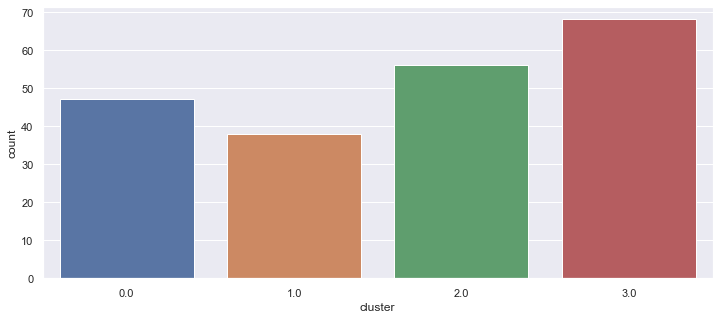

In [342]:
labels = pd.DataFrame(est.labels_)
labels.columns = ['cluster']
df_clusters = pd.concat([df_clust, labels], axis=1)

sns.countplot(df_clusters.cluster)

In [346]:
old_df["Группа"]=est.fit_predict(x)

In [347]:
mean_df = old_df.groupby('Группа').mean()
mean_df

,sex,age,common_count,followers_count,transparency_level,Студенты,Бауманка,Одежда,Приднестровье,Магазин,Музыка,Москва,Фильмы,Новости,bad_habits
Группа,,,,,,,,,,,,,,,
0,1.533333,8.45,12.716667,421.000000,3.833333,9.766667,8.966667,4.333333,3.666667,2.600000,4.916667,58.600000,4.500000,2.633333,1.750000
1,1.500000,7.513889,12.472222,618.458333,4.166667,8.694444,3.430556,4.486111,41.472222,9.972222,10.375000,7.180556,4.791667,9.555556,1.652778
2,1.848485,9.393939,13.757576,220.727273,4.272727,17.151515,69.212121,0.000000,3.454545,2.242424,0.424242,5.848485,1.666667,0.000000,1.030303
3,1.477273,7.818182,14.522727,861.795455,4.090909,4.636364,5.590909,0.704545,10.045455,3.477273,5.613636,12.613636,52.750000,4.363636,1.272727


<AxesSubplot:xlabel='Группа'>

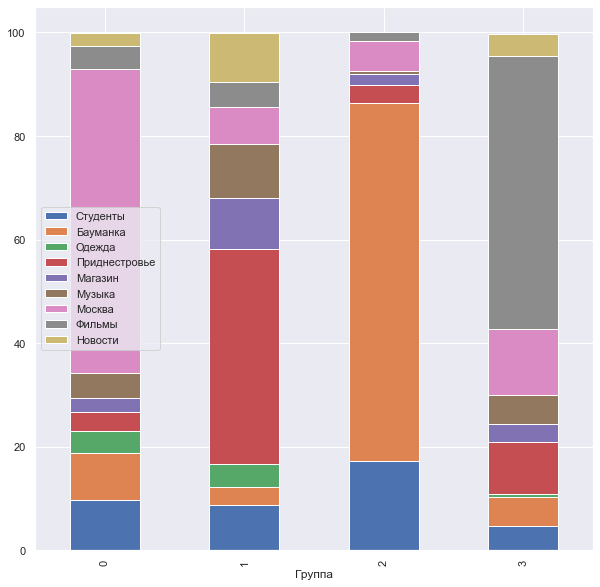

In [348]:
mean_df[["Студенты","Бауманка","Одежда","Приднестровье","Магазин","Музыка","Москва","Фильмы","Новости"]].reset_index().plot.bar(x="Группа",stacked=True,figsize=(10,10))

In [349]:
old_df.loc[old_df["sex"] == 1,"sex"]="Женский"
old_df.loc[old_df["sex"] == 2,"sex"]="Мужской"

In [350]:
clusters={}
clusters["Москва"]=old_df[old_df["Группа"] == 0]
clusters["Приднестровье"]=old_df[old_df["Группа"] == 1]
clusters["Бауманка"]=old_df[old_df["Группа"] == 2]
clusters["Фильмы"]=old_df[old_df["Группа"] == 3]

## **Подбор целевой аудитории**

In [351]:
# ! pip install ipywidgets
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

In [353]:
cluster=widgets.Dropdown(
    options=clusters.keys(),
    value=list(clusters.keys())[0],
    description = "Интересы"
)
vozrast=widgets.Dropdown(
    options=["Любой","Только 18+"],
    value="Любой",
    description = "Возраст"
)
pol=widgets.Dropdown(
    options=["Любой","Мужской","Женский"],
    value="Любой",
    description = "Пол"
)
knopka=widgets.Button(description='Сформировать список id')

def kk(a):
  t=clusters[cluster.value]
  if vozrast.value == "Только 18+":
    t=t[t["age"]>=18]
  if pol.value != "Любой":
    t=t[t["sex"] == pol.value]
  # print(t[["first_name","last_name","age","sex"]])
  # print(list(t.index))
  # print()
  # clear_output()
  display(t[["first_name","last_name","age","sex"]])
  # display(list(t.index))

knopka.on_click(kk)

m=[cluster,vozrast,pol,knopka]
widgets.VBox(children=m)


,first_name,last_name,age,sex
id,,,,
37383953,Кристиан,Караманов,0,Мужской
43558478,Iskander,Kaiyrov,0,Мужской
58745121,Дмитрий,Дурбайло,25,Мужской
71522203,Алексей,Воякин,0,Мужской
108635338,Айрат,Яфизов,24,Мужской
186835565,Илья,Шустиков,0,Мужской
189092168,Павел,Хетагуров,0,Мужской
205455408,Марк,Марков,26,Мужской
210948178,Vladimir,Kochetkov,24,Мужской
